# Chapter 10 · Stratified sampling and conditional Monte Carlo: interactive demos

Companion to Chapter 10 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/10-stratification.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the test case is $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price 7.36429), and
$S_T = S\exp(\nu T + \sigma\sqrt T Z)$ with $\nu = r-y-\sigma^2/2$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import time
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown
from scipy.special import ndtr

from mfe230d.bs import TEST_CASE, call, put
from mfe230d.paths import brownian_paths, time_grid
from mfe230d.rng import norm_inv
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style
from mfe230d.stratified import (HESTON_LAB, allocation_factors, asian_call_values, equiprobable_edges,
                                heston_put_samples, latin_hypercube, linear_direction, neyman_allocation,
                                normal_edges, open_uniforms, poststratified_estimate, proportional_allocation,
                                strata_of, stratified_estimate, stratified_normals, stratified_projection,
                                stratum_moments, terminal_price, terminal_stratified_normals)

use_style()
GREEN = "#1BAF7A"
P = TEST_CASE
S, K, T, r, y, SIG = (P[k] for k in ("S", "K", "T", "r", "y", "sigma"))
DISC = np.exp(-r * T)

def payoff(kind, strike):
    if kind == "call":
        return lambda z: DISC * np.maximum(terminal_price(z, S, T, r, y, SIG) - strike, 0.0)
    return lambda z: DISC * np.maximum(strike - terminal_price(z, S, T, r, y, SIG), 0.0)

def strike_z(strike):
    return (np.log(strike / S) - (r - y - 0.5 * SIG**2) * T) / (SIG * np.sqrt(T))

## 1. Strata in one dimension: proportional and Neyman allocation

Cut the uniform $U$ (and so $Z=N^{-1}(U)$) into $H$ equiprobable strata. Proportional allocation puts $n/H$ draws in
each and removes the variance *between* strata (Theorem 10.1); Neyman allocation puts $n_h\propto p_h\sigma_h$ draws
in stratum $h$ (Proposition 10.3). The left panel shows the payoff against $u$ and its stratum means; the right
panel shows where the draws go. The variance factors are exact (stratum moments by quadrature); the estimates
below the figure come from one run.

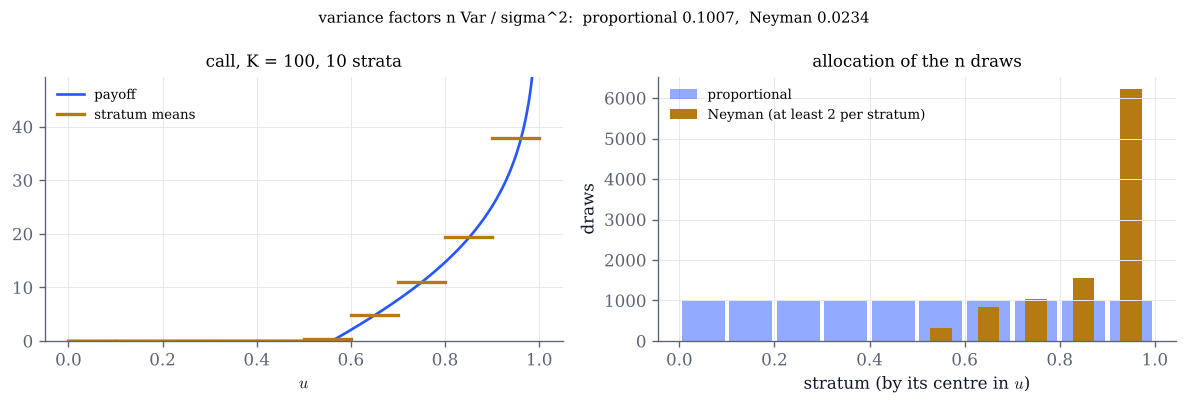

exact price 7.36429
plain        7.43400 ± 0.12436
proportional 7.37492 ± 0.03798
Neyman       7.34447 ± 0.01909


In [2]:
def strata_demo(kind="call", strike=100.0, H=10, n=10_000, seed=0):
    f = payoff(kind, strike)
    zs = strike_z(strike)
    p, m, v = stratum_moments(f, normal_edges(H), kinks=(zs,))
    fac = allocation_factors(p, m, v)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    u = np.linspace(1e-4, 1 - 1e-4, 2001)
    ax.plot(u, f(norm_inv(u)), color=COBALT, label="payoff")
    e = equiprobable_edges(H)
    for h in range(H):
        ax.plot([e[h], e[h + 1]], [m[h], m[h]], color=GOLD, lw=2, label="stratum means" if h == 0 else None)
    ax.set(xlabel="$u$", ylim=(0, max(5, 1.3 * m.max())), title=f"{kind}, K = {strike:g}, {H} strata")
    ax.legend(fontsize=8)
    ney = neyman_allocation(n, p, np.sqrt(v), minimum=2)
    prop = proportional_allocation(n, p)
    centres = 0.5 * (e[1:] + e[:-1])
    bx.bar(centres, prop, width=0.9 / H, color=COBALT, alpha=0.5, label="proportional")
    bx.bar(centres, ney, width=0.45 / H, color=GOLD, label="Neyman (at least 2 per stratum)")
    bx.set(xlabel="stratum (by its centre in $u$)", ylabel="draws", title="allocation of the n draws")
    bx.legend(fontsize=8)
    fig.suptitle(f"variance factors n Var / sigma^2:  proportional {fac['proportional']:.4f},  "
                 f"Neyman {fac['neyman']:.4f}", fontsize=9)
    fig.tight_layout()
    plt.show()
    rng = np.random.default_rng(seed)
    x = f(rng.standard_normal(n))
    exact = float(call(S, strike, T, r, y, SIG) if kind == "call" else put(S, strike, T, r, y, SIG))
    print(f"exact price {exact:.5f}")
    print(f"plain        {x.mean():.5f} ± {x.std(ddof=1) / np.sqrt(n):.5f}")
    for name, counts in (("proportional", prop), ("Neyman", ney)):
        z, lab = stratified_normals(counts, rng=rng)
        o = stratified_estimate(f(z), lab, p)
        print(f"{name:12s} {o['mean']:.5f} ± {o['se']:.5f}")

strata_demo()

In [3]:
# Explore: more strata, other strikes, the put. Where does Neyman send the draws, and why?
interact(strata_demo,
         kind=Dropdown(options=["call", "put"], value="call", description="payoff"),
         strike=FloatSlider(value=100, min=70, max=130, step=1, continuous_update=False, description="K"),
         H=IntSlider(value=10, min=1, max=200, continuous_update=False, description="strata H"),
         n=Dropdown(options=[2_000, 10_000, 100_000], value=10_000, description="n"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. Stratifying paths: which direction?

A path of $m$ dates needs $m$ normals; stratifying all of them is hopeless, so stratify one direction $v^\top Z$ and
fill in the rest (Proposition 10.7). Under the Brownian-bridge construction the first normal sets $W_T$; under the
increments construction it sets only the first increment; the direction of $\sum_j W_{t_j}$ follows the average.
The left panel shows one path per stratum of the chosen direction, the right panel the arithmetic Asian call:
standard error of the stratified estimator over that of plain sampling, at equal $n$.

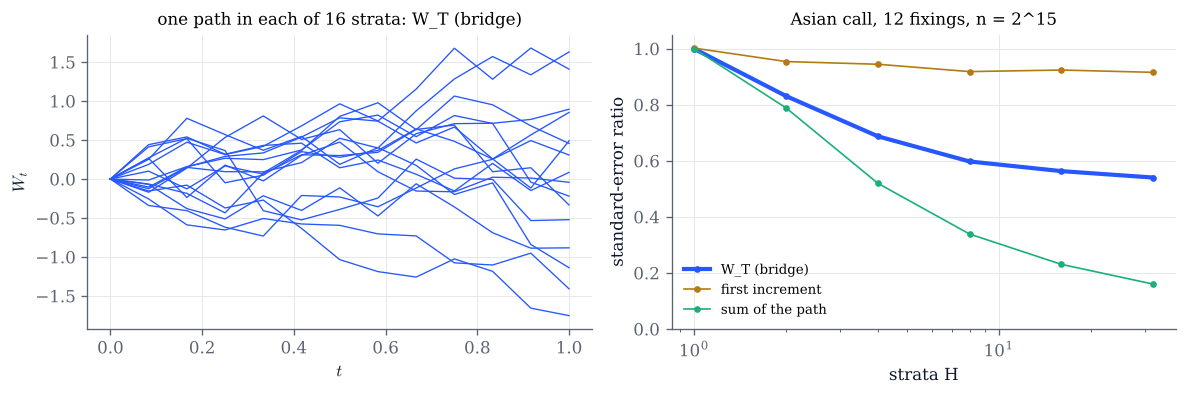

In [4]:
CHOICES = ["W_T (bridge)", "first increment", "sum of the path"]

def stratified_paths(choice, counts, m, rng):
    if choice == "sum of the path":
        xi, lab = stratified_normals(counts, rng=rng)
        return stratified_projection(linear_direction(time_grid(T, m)), xi, rng=rng), lab, "increments"
    Z, lab = terminal_stratified_normals(counts, m, rng=rng)
    return Z, lab, "bridge" if choice == "W_T (bridge)" else "increments"

def paths_demo(choice="W_T (bridge)", m=12, H=32, log2n=15, seed=0):
    rng = np.random.default_rng(seed)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    t = time_grid(T, m)
    Z, lab, meth = stratified_paths(choice, np.ones(16, dtype=int), m, rng)
    W = brownian_paths(t, Z=Z, method=meth)
    ax.plot(t, W.T, color=COBALT, lw=0.8)
    ax.set(xlabel="$t$", ylabel="$W_t$", title=f"one path in each of 16 strata: {choice}")
    n = 2**log2n
    sd = np.std(asian_call_values(rng.standard_normal((2**17, m)), S, K, T, r, y, SIG), ddof=1)
    Hs = [h for h in (1, 2, 4, 8, 16, 32, 64, 128, 256) if h <= H] or [1]
    for c, color in zip(CHOICES, (COBALT, GOLD, GREEN)):
        ratios = []
        for h in Hs:
            p = np.full(h, 1.0 / h)
            Zs, lb, mt = stratified_paths(c, proportional_allocation(n, p), m, rng)
            ratios.append(stratified_estimate(asian_call_values(Zs, S, K, T, r, y, SIG, mt), lb, p)["se"] * np.sqrt(n) / sd)
        bx.plot(Hs, ratios, "o-", ms=3, color=color, lw=2.5 if c == choice else 1.0, label=c)
    bx.set(xscale="log", xlabel="strata H", ylabel="standard-error ratio", ylim=(0, 1.05),
           title=f"Asian call, {m} fixings, n = 2^{log2n}")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

paths_demo()

In [5]:
# Explore: more fixings, more strata. Why does the sum of the path win for an Asian payoff?
interact(paths_demo,
         choice=Dropdown(options=CHOICES, value="W_T (bridge)", description="stratify"),
         m=IntSlider(value=12, min=2, max=64, continuous_update=False, description="fixings m"),
         H=IntSlider(value=32, min=1, max=256, continuous_update=False, description="max strata"),
         log2n=IntSlider(value=15, min=12, max=17, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 3. Latin hypercube sampling

A Latin hypercube sample of $n$ points has one point in each of the $n$ strata of every coordinate (Definition 10.9).
It integrates the additive part of an integrand as one-dimensional stratification does, and leaves the rest to
plain sampling (Proposition 10.10). The left panel compares a design with $n$ independent points; the right panel
shows $n\,\mathrm{Var}/\sigma^2$ against $n$ in dimension $d$ for three integrands, from independent designs.

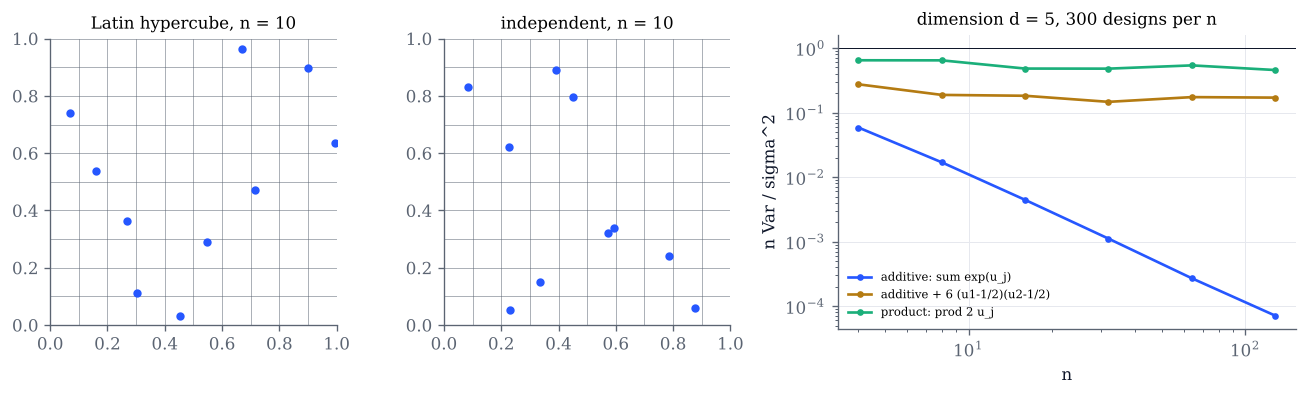

In [6]:
TESTS = {
    "additive: sum exp(u_j)": lambda U: np.exp(U).sum(axis=1),
    "additive + 6 (u1-1/2)(u2-1/2)": lambda U: np.exp(U).sum(axis=1) + 6 * (U[:, 0] - 0.5) * (U[:, 1] - 0.5),
    "product: prod 2 u_j": lambda U: np.prod(2 * U, axis=1),
}

def lhs_demo(n=10, d=5, reps=300, seed=0):
    rng = np.random.default_rng(seed)
    fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
    for axx, pts, title in ((ax, latin_hypercube(n, 2, rng=rng), "Latin hypercube"),
                            (bx, rng.random((n, 2)), "independent")):
        for k in range(n + 1):
            axx.axhline(k / n, color=GREY, lw=0.3); axx.axvline(k / n, color=GREY, lw=0.3)
        axx.plot(pts[:, 0], pts[:, 1], "o", ms=4, color=COBALT)
        axx.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", title=f"{title}, n = {n}")
        axx.grid(False)
    ns = [4, 8, 16, 32, 64, 128]
    for (name, g), color in zip(TESTS.items(), (COBALT, GOLD, GREEN)):
        var = g(rng.random((2**18, d))).var()
        vals = [nn * np.var([g(latin_hypercube(nn, d, rng=rng)).mean() for _ in range(reps)], ddof=1) / var for nn in ns]
        cx.plot(ns, vals, "o-", ms=3, color=color, label=name)
    cx.axhline(1, color=INK, lw=0.6)
    cx.set(xscale="log", yscale="log", xlabel="n", ylabel="n Var / sigma^2", title=f"dimension d = {d}, {reps} designs per n")
    cx.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

lhs_demo()

In [7]:
# Explore: does the dimension matter for the additive function? For the product?
interact(lhs_demo,
         n=IntSlider(value=10, min=2, max=40, continuous_update=False, description="points n"),
         d=IntSlider(value=5, min=2, max=20, continuous_update=False, description="dimension d"),
         reps=IntSlider(value=300, min=100, max=1000, step=100, continuous_update=False, description="designs"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 4. Conditional Monte Carlo: conditioning on the volatility path

In the Heston model, given the variance path the log-price is Gaussian, and the Black--Scholes formula with spot
$\tilde S=S\exp(\rho I_T-\frac12\rho^2Q_T)$ and volatility $\tilde\sigma=\sqrt{(1-\rho^2)Q_T/T}$ gives the
conditional price (Proposition 10.12). The plain estimator draws one more normal per path; the conditional estimator
averages the Black--Scholes put over the same variance paths. The variance is sampled exactly on 64 steps.

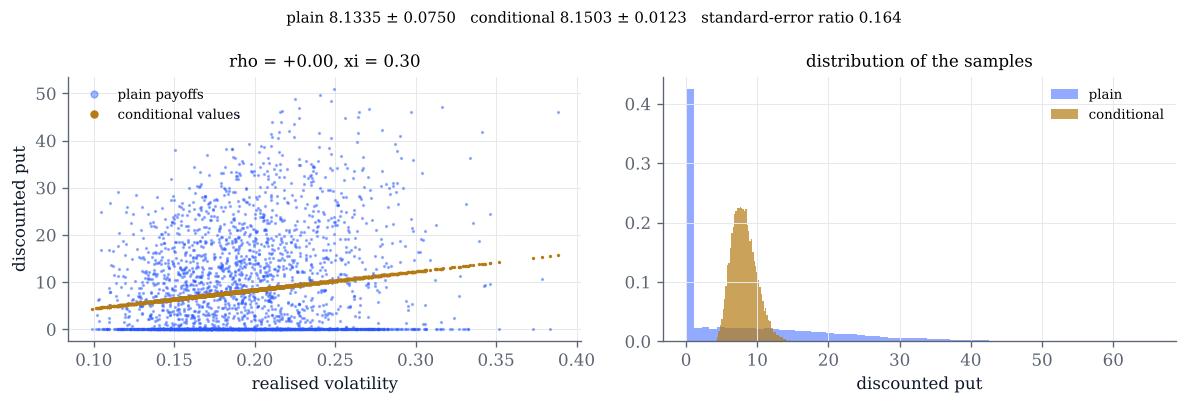

In [8]:
def mixing_demo(rho=0.0, xi=0.3, kappa=2.0, n=20_000, seed=0):
    H_ = HESTON_LAB
    s = heston_put_samples(S, K, T, r, y, rho, H_["v0"], kappa, H_["theta"], xi, m=64, n=n, seed=seed)
    a, b = s["plain"], s["conditional"]
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    k = min(n, 3000)
    vol = np.sqrt(s["Q"][:k] / T)
    ax.plot(vol, a[:k], ".", ms=2, color=COBALT, alpha=0.4, label="plain payoffs")
    ax.plot(vol, b[:k], ".", ms=2, color=GOLD, label="conditional values")
    ax.set(xlabel="realised volatility", ylabel="discounted put", title=f"rho = {rho:+.2f}, xi = {xi:.2f}")
    ax.legend(fontsize=8, markerscale=4)
    bx.hist(a, bins=60, color=COBALT, alpha=0.5, density=True, label="plain")
    bx.hist(b, bins=60, color=GOLD, alpha=0.7, density=True, label="conditional")
    bx.set(xlabel="discounted put", title="distribution of the samples")
    bx.legend(fontsize=8)
    sa, sb = a.std(ddof=1) / np.sqrt(n), b.std(ddof=1) / np.sqrt(n)
    fig.suptitle(f"plain {a.mean():.4f} ± {sa:.4f}   conditional {b.mean():.4f} ± {sb:.4f}   "
                 f"standard-error ratio {sb / sa:.3f}", fontsize=9)
    fig.tight_layout()
    plt.show()

mixing_demo()

In [9]:
# Explore: how does the gain depend on the correlation? At rho = -1 there is nothing left to integrate out.
interact(mixing_demo,
         rho=FloatSlider(value=0.0, min=-0.99, max=0.5, step=0.01, continuous_update=False, description="rho"),
         xi=FloatSlider(value=0.3, min=0.1, max=0.5, step=0.05, continuous_update=False, description="xi"),
         kappa=FloatSlider(value=2.0, min=0.5, max=5.0, step=0.5, continuous_update=False, description="kappa"),
         n=Dropdown(options=[5_000, 20_000, 50_000], value=20_000, description="paths"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 5. The laboratory with measured times

Efficiency is $1/(\text{variance}\times\text{cost})$ (Definition 6.9 in Chapter 6). A stratified draw costs one
inversion $N^{-1}(u)$; NumPy's normal generator is faster. This cell times plain sampling with NumPy normals and with
inversion, proportional and Neyman stratification and post-stratification, for the call at strike $K$, and
reports the efficiencies relative to plain sampling with NumPy normals.

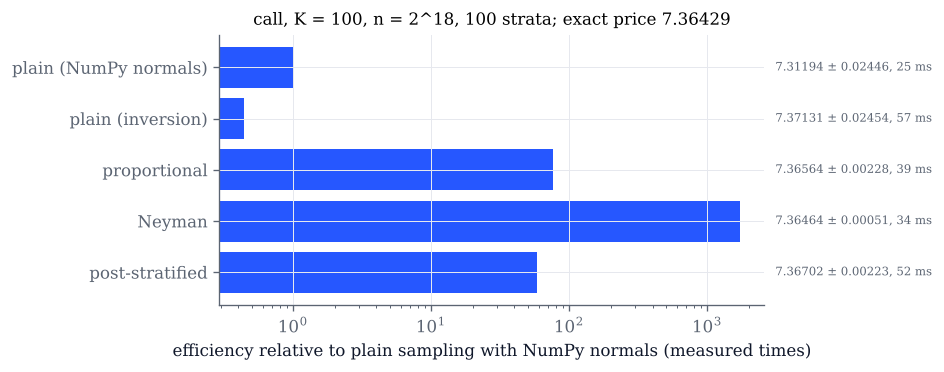

In [10]:
def lab_demo(strike=100.0, H=100, log2n=18, seed=1):
    f = payoff("call", strike)
    n = 2**log2n
    p, m, v = stratum_moments(f, normal_edges(H), kinks=(strike_z(strike),))
    rng = np.random.default_rng(seed)
    def timed(fn):
        t0 = time.perf_counter(); out = fn(); return out, time.perf_counter() - t0
    def plain_numpy():
        x = f(rng.standard_normal(n)); return dict(mean=x.mean(), se=x.std(ddof=1) / np.sqrt(n))
    def plain_inversion():
        x = f(norm_inv(open_uniforms(rng, n))); return dict(mean=x.mean(), se=x.std(ddof=1) / np.sqrt(n))
    def proportional():
        z, lab = stratified_normals(proportional_allocation(n, p), rng=rng); return stratified_estimate(f(z), lab, p)
    def neyman():
        z, lab = stratified_normals(neyman_allocation(n, p, np.sqrt(v), minimum=2), rng=rng)
        return stratified_estimate(f(z), lab, p)
    def post():
        z = rng.standard_normal(n); return poststratified_estimate(f(z), strata_of(ndtr(z), equiprobable_edges(H)), p)
    methods = {"plain (NumPy normals)": plain_numpy, "plain (inversion)": plain_inversion,
               "proportional": proportional, "Neyman": neyman, "post-stratified": post}
    res = {k: timed(fn) for k, fn in methods.items()}
    (o0, t0) = res["plain (NumPy normals)"]
    names = list(res)
    eff = [o0["se"] ** 2 * t0 / (res[k][0]["se"] ** 2 * res[k][1]) for k in names]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(names[::-1], eff[::-1], color=COBALT)
    ax.set(xscale="log", xlabel="efficiency relative to plain sampling with NumPy normals (measured times)",
           title=f"call, K = {strike:g}, n = 2^{log2n}, {H} strata; exact price {float(call(S, strike, T, r, y, SIG)):.5f}")
    for i, k in enumerate(names[::-1]):
        o, t = res[k]
        ax.text(1.02, i, f"{o['mean']:.5f} ± {o['se']:.5f}, {1e3 * t:.0f} ms", va="center", fontsize=7,
                transform=ax.get_yaxis_transform(), color=GREY)
    fig.tight_layout()
    plt.show()

lab_demo()

In [11]:
# Explore: timings vary from machine to machine; run it a few times.
interact(lab_demo,
         strike=FloatSlider(value=100, min=70, max=130, step=5, continuous_update=False, description="K"),
         H=IntSlider(value=100, min=2, max=1000, continuous_update=False, description="strata H"),
         log2n=IntSlider(value=18, min=14, max=21, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## Things to try

- In section 1, put the strike at 130 and use few strata. Why does proportional allocation help so little, and what
  does Neyman allocation do with the strata where the call is worthless?
- In section 2, increase the number of fixings $m$. Does stratifying $W_T$ help more or less? And the sum of the path?
- In section 3, raise the dimension $d$ for the additive function: does Latin hypercube sampling get worse?
- In section 4, set $\rho$ close to $-1$. What is left of the gain, and why? Then set $\rho=0$ and vary $\xi$.
- In section 5, compare the efficiency of proportional stratification against both plain estimators: the cost of
  the inverse normal matters.